# The Winner's Curse of Planning: pilot experiments (ICWM 2027)

**What this notebook is.** The cheap first stage of the paper plan. It tests, in a controlled environment where the
true dynamics are known, whether (1) a planner's predicted cost gets more optimistic as search grows,
(2) true success saturates or reverses when some candidates are off the model's data support,
(3) a label-free *cross-fit* estimator can measure that optimism, and (4) bias-aware planners help at matched compute.

**What it is not.** Evidence about DINO-WM / LeWM / TD-MPC2. Those released-checkpoint runs (stage 2) only start if the
gates in the last section pass here.

**Where things run**

| Part | Where | Cost |
|---|---|---|
| A. Theory simulation | local CPU | free |
| B. Learned-model pilot (E1, E3, E4) | local CPU (about 25 min on 2 cores) | free |
| C. Same pilot, scaled up | Modal GPU (`modal_app.py`) | start with `--smoke`, then check the printed cost |
| D. Gates | local | free |

Related work you must cite and position against (found in the literature check): *Search or Scoring? Diagnosing Why
Visual World-Model Planners Fail* (arXiv 2611.25347) already states the i.i.d. optimism result
sigma*sqrt(2 ln N) and the optimizer's-curse framing. This pilot therefore treats Result 1 as background and tests what
is left: the off-support extension (Result 2), the label-free estimator, and budget-aware planning.

In [19]:
import os, sys, subprocess, importlib, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
sys.path.insert(0, os.getcwd())
import wcp_core as W, wcp_plots as P
importlib.reload(W); importlib.reload(P)
os.makedirs("results", exist_ok=True); os.makedirs("figures", exist_ok=True)

def run(cmd):
    # Run a command and stream its output INTO this cell. (Plain subprocess.run sends output to the
    # Jupyter server log, which is why Modal runs can look like they did nothing.)
    env = dict(os.environ, PYTHONUTF8="1", PYTHONIOENCODING="utf-8")   # Windows: Modal prints UTF-8
    p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1,
                         encoding="utf-8", errors="replace", env=env)
    for line in p.stdout:
        print(line, end="", flush=True)
    p.wait()
    print(f"\n[exit code {p.returncode}]")
    return p.returncode

print("ready | working directory:", os.getcwd())
assert os.path.exists("modal_app.py"), "Open the notebook from inside the icwm_pilot folder (modal_app.py must be next to it)."

ready | working directory: e:\Web_downloads\icwm_pilot\icwm_pilot


## A. Theory simulation (Results 1 and 2)
Result 1 is the standard i.i.d. winner's-curse formula. Result 2 is the off-support extension: a small share of candidates has large model error, so the *winning group* switches as N grows.

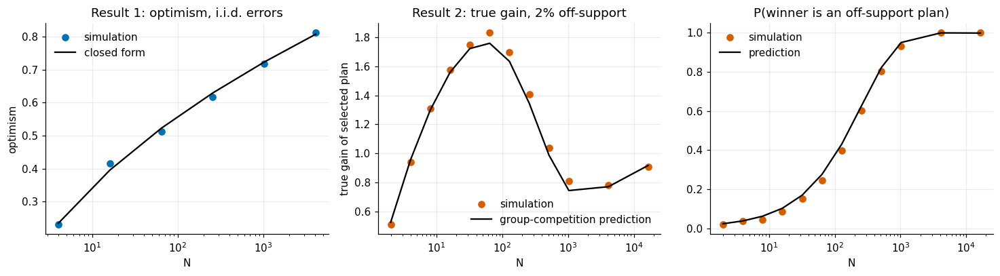

simulated peak of true gain at N* = 64 | predicted N* = 64 | corr = 0.998


In [2]:
Ns_t = [2, 4, 8, 16, 32, 64, 128, 256, 512, 1024, 4096, 16384]
gauss = W.theory_gaussian([4, 16, 64, 256, 1024, 4096], sigma=0.5, reps=3000)
two = W.theory_two_group(Ns_t, s=1.0, sig_lo=0.3, sig_hi=3.0, p_hi=0.02, reps=2000)
fig = P.fig_theory(gauss, two); fig.savefig("figures/fig_theory.png", dpi=160, bbox_inches="tight"); plt.show()
g, q = [r["gain_mc"] for r in two], [r["gain_pred"] for r in two]
print("simulated peak of true gain at N* =", Ns_t[int(np.argmax(g))], "| predicted N* =", Ns_t[int(np.argmax(q))],
      "| corr =", round(float(np.corrcoef(g, q)[0, 1]), 3))

## B. Learned-model pilot on CPU
Environment: 2D point mass with a swirl field, a high-drag disc and bouncing walls. Offline data comes only from
x < 0.6, so the right side (including the drag disc) is **off-support**. Two independent ensembles of 5 MLP dynamics
models; 36 start-goal pairs each (18 *near* goals in-support, 18 *far* goals off-support). Every model also acts as a
proposer while the other four act as held-out evaluators (this is the cross-fit estimator).

In [3]:
# ~10-12 min per ensemble; the two ensembles run in parallel. Skipped if results already exist.
need = [s for s in (0, 1) if not os.path.exists(f"results/planners_e{s}.csv")]
procs = [subprocess.Popen([sys.executable, "run_pilot.py", "--seed", str(s), "--M", "36"]) for s in need]
for p_ in procs: p_.wait()
df = pd.concat([pd.read_csv(f"results/sweep_e{s}.csv") for s in (0, 1)], ignore_index=True)
dp = pd.concat([pd.read_csv(f"results/planners_e{s}.csv") for s in (0, 1)], ignore_index=True)
# pairs differ per ensemble: make pair ids unique so the cluster bootstrap treats them as separate units
for d_ in (df, dp): d_["pair"] = d_["ensemble"] * 1000 + d_["pair"]
print(len(df), "sweep rows;", len(dp), "planner rows")

4320 sweep rows; 4536 planner rows


### E1: optimism and success versus search budget

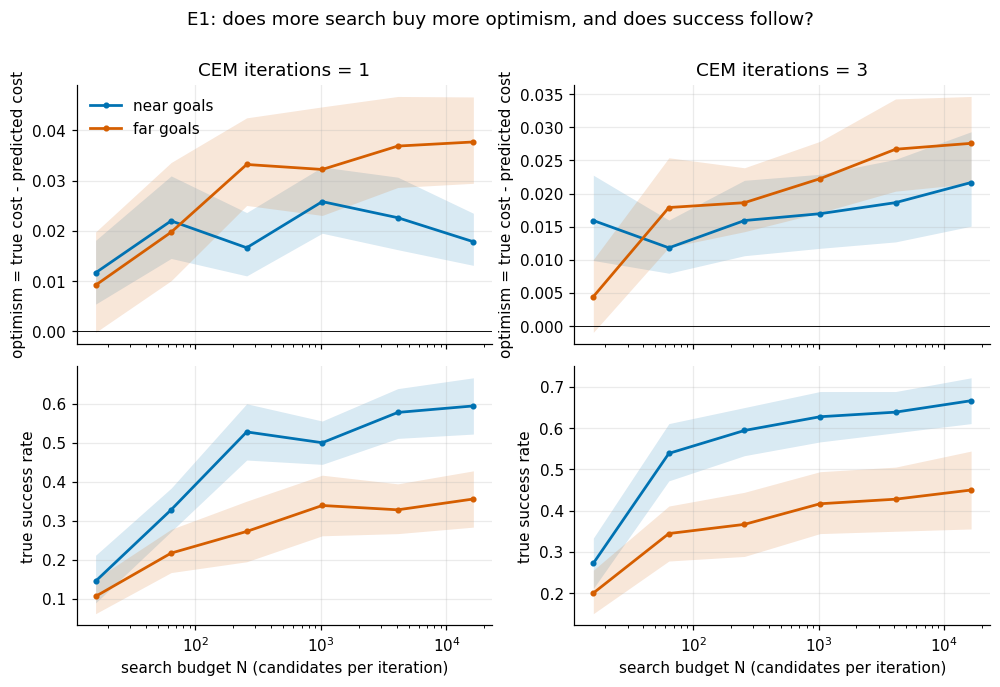

 tag     N  optimism      lo     hi  n_pairs
 far    16    0.0044 -0.0009 0.0100       36
 far    64    0.0179  0.0119 0.0254       36
 far   256    0.0186  0.0142 0.0239       36
 far  1024    0.0222  0.0171 0.0279       36
 far  4096    0.0267  0.0204 0.0343       36
 far 16384    0.0276  0.0215 0.0347       36
near    16    0.0159  0.0099 0.0228       36
near    64    0.0118  0.0080 0.0160       36
near   256    0.0159  0.0106 0.0220       36
near  1024    0.0170  0.0117 0.0229       36
near  4096    0.0186  0.0127 0.0252       36
near 16384    0.0217  0.0151 0.0293       36


In [4]:
fig = P.fig_scaling(df, iters_list=(1, 3)); fig.savefig("figures/fig_E1_scaling.png", dpi=160, bbox_inches="tight"); plt.show()
print(W.summarize(df[df.iters == 3], ["tag", "N"], "optimism").round(4).to_string(index=False))

### E3: can optimism be estimated without the environment?

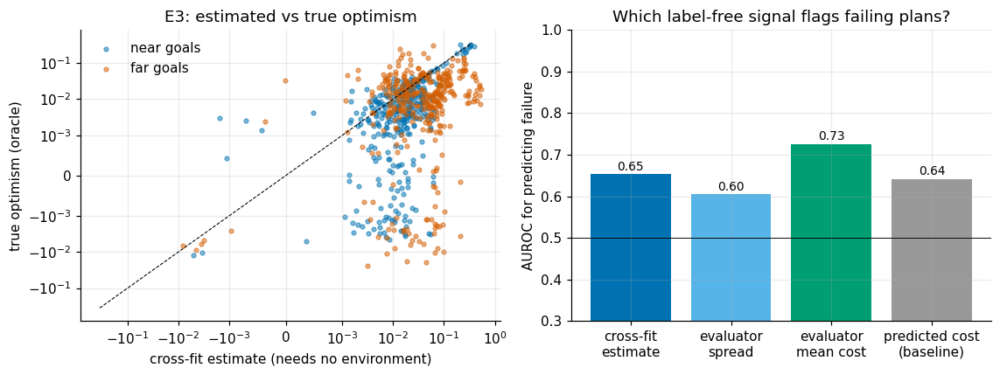

{'spearman_all': 0.411, 'spearman_within_cell_mean': 0.392, 'auroc_est_optimism': 0.653, 'auroc_oth_std': 0.605, 'auroc_pred_cost_baseline': 0.642, 'auroc_oth_mean': 0.726}


In [5]:
fig, q = P.fig_estimator(df); fig.savefig("figures/fig_E3_estimator.png", dpi=160, bbox_inches="tight"); plt.show()
print({k: round(v, 3) for k, v in q.items()})

### E4: planners at matched compute
`single` = plain CEM; `meanens`/`lcb` = ensemble planners (5x model evaluations); `crossfit` = propose with one member, re-rank top candidates with the others; `budget_select` = run several N and keep the plan the held-out members rate best.

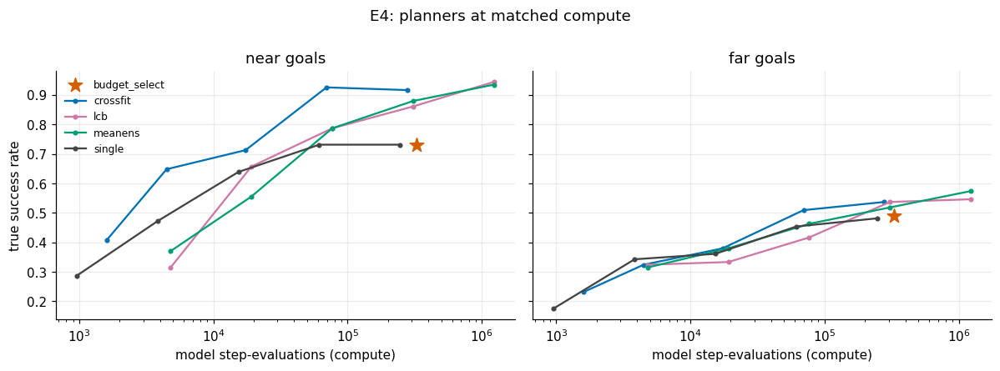

 tag        method  success  s_lo  s_hi  mean_dist     evals
 far        single    0.481 0.370 0.593      0.128  245760.0
 far      crossfit    0.537 0.426 0.648      0.111  278480.0
 far budget_select    0.491 0.370 0.602      0.113  327760.0
 far           lcb    0.546 0.417 0.676      0.106 1228800.0
 far       meanens    0.574 0.435 0.704      0.111 1228800.0
near        single    0.731 0.639 0.815      0.077  245760.0
near      crossfit    0.917 0.852 0.972      0.063  278480.0
near budget_select    0.731 0.639 0.824      0.073  327760.0
near           lcb    0.944 0.898 0.981      0.055 1228800.0
near       meanens    0.935 0.889 0.972      0.059 1228800.0


In [6]:
fig = P.fig_planners(dp); fig.savefig("figures/fig_E4_planners.png", dpi=160, bbox_inches="tight"); plt.show()
print(P.planner_table(dp).round(3).to_string(index=False))

## C. Scale up on Modal GPUs from this notebook

One-time setup (in the VS Code terminal, not in this notebook): `pip install modal`, then `modal setup` and sign in.
Then run the cells below **in order**. Always do the smoke run first and read the cost line it prints. Output now streams into the cell; if a cell prints nothing, something is wrong with the kernel, not Modal.

In [2]:
# 1) Is Modal installed, and which workspace are you logged into? (Compare the workspace name with the
#    one selected at the top-left of modal.com/apps. Runs only show up in the workspace you are logged into.)
run([sys.executable, "-m", "modal", "--version"])
run([sys.executable, "-m", "modal", "profile", "current"])

modal client version: 1.4.2

[exit code 0]
smjubaer-0-00

[exit code 0]


0

In [8]:
# 2) SMOKE RUN: one tiny ensemble on one L4 GPU. Output streams below. Expect: image build (first time
#    takes a few minutes), then 'trained in ...s', then a cost line, then 'saved results/gpu_*_smoke.csv'.
rc = run([sys.executable, "-m", "modal", "run", "modal_app.py", "--smoke"])

- Initializing...
✓ Initialized. View run at 
https://modal.com/apps/smjubaer-0-00/main/ap-bBZBcCwdYkUGkP2St6SQoh
- Initializing...
- Initializing...

- Creating objects...
\ Creating objects...
/ Creating objects...
| Creating objects...
├── - Creating mount e:\Web_downloads\icwm_pilot\icwm_pilot\modal_app.py: 
│   Uploaded 0/1 files
└── - Creating mount PythonPackage:wcp_core: Uploaded 0/1 files
- Creating objects...
├── | Creating mount e:\Web_downloads\icwm_pilot\icwm_pilot\modal_app.py: 
│   Uploaded 0/1 files
└── | Creating mount PythonPackage:wcp_core: Uploaded 0/1 files
| Creating objects...
├── - Creating mount e:\Web_downloads\icwm_pilot\icwm_pilot\modal_app.py: 
│   Uploaded 0/1 files
└── - Creating mount PythonPackage:wcp_core: Uploaded 0/1 files
- Creating objects...
├── | Creating mount e:\Web_downloads\icwm_pilot\icwm_pilot\modal_app.py: 
│   Uploaded 0/1 files
└── | Creating mount PythonPackage:wcp_core: Finalizing index of 1 files
| Creating objects...
├── - Creating m

In [ ]:
# # 3) FULL RUN (3 ensembles in parallel on L4s). Set RUN_FULL=True only after the smoke run worked.
# RUN_FULL = False
# if RUN_FULL:
#     run([sys.executable, "-m", "modal", "run", "modal_app.py", "--seeds", "3", "--M", "60"])

In [14]:
# 3) FULL RUN (3 ensembles in parallel on L4s). Set RUN_FULL=True only after the smoke run worked.
RUN_FULL = True
if RUN_FULL:
    run([sys.executable, "-m", "modal", "run", "modal_app.py", "--seeds", "3", "--n-pairs", "60"])

- Initializing...
✓ Initialized. View run at 
https://modal.com/apps/smjubaer-0-00/main/ap-46FzRs5XBoRqRtLX6RnYKY
- Initializing...
- Initializing...

- Creating objects...
| Creating objects...
- Creating objects...
├── - Creating mount e:\Web_downloads\icwm_pilot\icwm_pilot\modal_app.py: 
│   Uploaded 0/1 files
└── - Creating mount PythonPackage:wcp_core: Uploaded 0/1 files
| Creating objects...
├── | Creating mount e:\Web_downloads\icwm_pilot\icwm_pilot\modal_app.py: 
│   Uploaded 0/1 files
└── | Creating mount PythonPackage:wcp_core: Uploaded 0/1 files
- Creating objects...
├── - Creating mount e:\Web_downloads\icwm_pilot\icwm_pilot\modal_app.py: 
│   Uploaded 0/1 files
└── - Creating mount PythonPackage:wcp_core: Uploaded 0/1 files
| Creating objects...
├── | Creating mount e:\Web_downloads\icwm_pilot\icwm_pilot\modal_app.py: 
│   Uploaded 0/1 files
└── | Creating mount PythonPackage:wcp_core: Uploaded 0/1 files
- Creating objects...
├── - Creating mount e:\Web_downloads\icwm_pilo

In [15]:
# 4) Where did the results go? Local CSVs, the Modal volume, and Modal's own app list.
print("local result files:", sorted(f for f in os.listdir("results") if f.startswith("gpu_")))
run([sys.executable, "-m", "modal", "volume", "ls", "wcp-results"])
run([sys.executable, "-m", "modal", "app", "list"])

local result files: ['gpu_planners_full.csv', 'gpu_planners_smoke.csv', 'gpu_sweep_full.csv', 'gpu_sweep_smoke.csv']
gpu_sweep_full_e102.csv
gpu_planners_full_e102.csv
gpu_sweep_full_e101.csv
gpu_planners_full_e101.csv
gpu_sweep_full_e100.csv
gpu_planners_full_e100.csv
gpu_sweep_smoke_e100.csv
gpu_planners_smoke_e100.csv

[exit code 0]
                                            Apps                               
┌───────────────────────────┬─────────────┬─────────┬───────┬───────────────┬──
│ App ID                    │ Description │ State   │ Tasks │ Created at    │ S
├───────────────────────────┼─────────────┼─────────┼───────┼───────────────┼──
│ ap-46FzRs5XBoRqRtLX6RnYKY │ wcp-pilot   │ stopped │ 0     │ 2026-11-21    │ 2
│                           │             │         │       │ 02:27         │ 0
│                           │             │         │       │ Bangladesh    │ B
│                           │             │         │       │ Standard Time │ S
│                     

0

loaded full run: 18900 sweep rows, 11340 planner rows
             pred  oracle  optimism  success
tag  N                                      
far  16     0.054   0.061     0.006    0.201
     64     0.022   0.042     0.020    0.298
     256    0.011   0.034     0.023    0.361
     1024   0.006   0.032     0.026    0.383
     4096   0.003   0.031     0.028    0.412
     16384  0.001   0.030     0.029    0.394
     65536  0.001   0.030     0.030    0.402
near 16     0.036   0.042     0.006    0.313
     64     0.016   0.023     0.007    0.511
     256    0.008   0.017     0.008    0.615
     1024   0.004   0.013     0.009    0.684
     4096   0.002   0.011     0.009    0.713
     16384  0.001   0.010     0.009    0.747
     65536  0.001   0.009     0.009    0.750


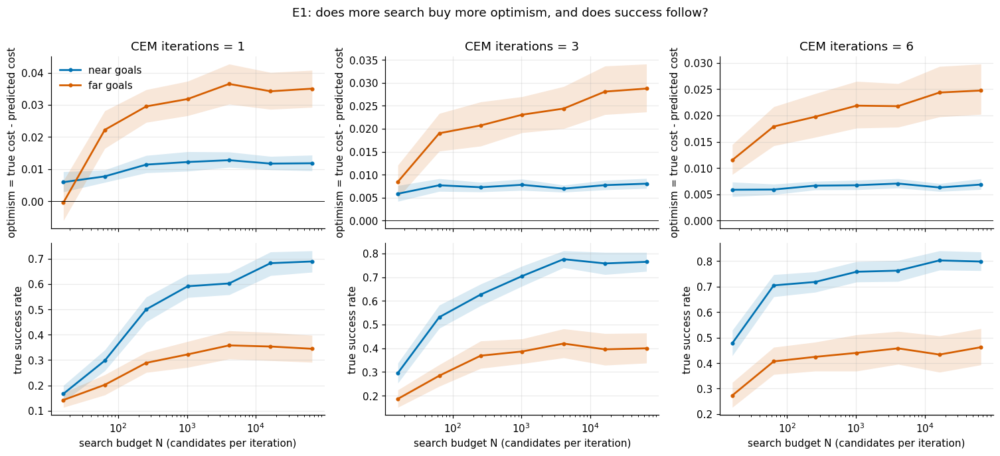

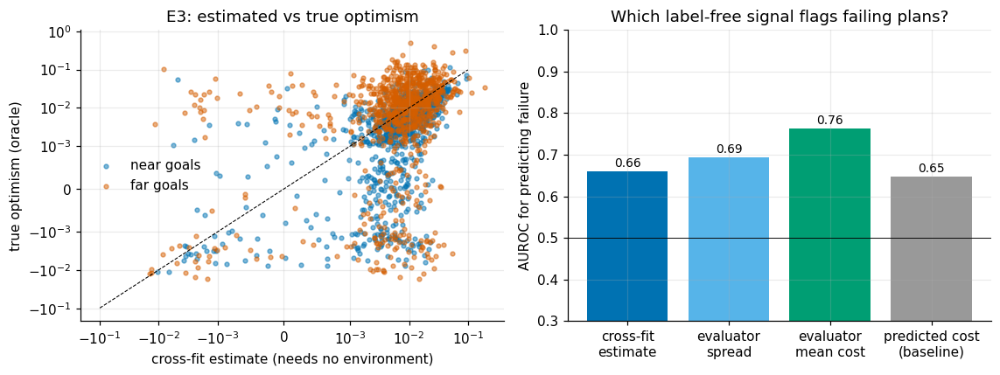

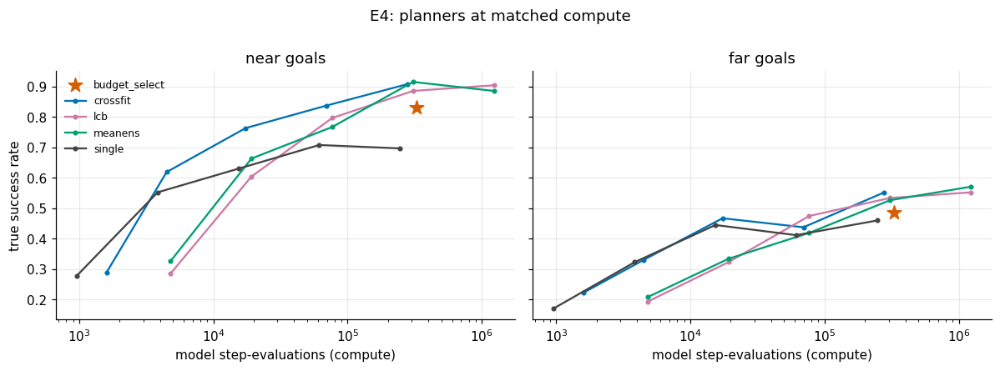

In [16]:
# 5) Load GPU results (full run if present, otherwise the smoke run) and reuse the same figures.
tag = "full" if os.path.exists("results/gpu_sweep_full.csv") else ("smoke" if os.path.exists("results/gpu_sweep_smoke.csv") else None)
if tag is None:
    print("No GPU result CSVs in ./results yet. Run cell 2 and read its output for errors.")
else:
    dg, dgp = pd.read_csv(f"results/gpu_sweep_{tag}.csv"), pd.read_csv(f"results/gpu_planners_{tag}.csv")
    for d_ in (dg, dgp): d_["pair"] = d_["ensemble"] * 1000 + d_["pair"]
    print(f"loaded {tag} run:", len(dg), "sweep rows,", len(dgp), "planner rows")
    print(dg.groupby(["tag", "N"])[["pred", "oracle", "optimism", "success"]].mean().round(3))
    if tag == "full":
        P.fig_scaling(dg, iters_list=(1, 3, 6)).savefig("figures/fig_E1_scaling_gpu.png", dpi=160, bbox_inches="tight")
        P.fig_estimator(dg)[0].savefig("figures/fig_E3_estimator_gpu.png", dpi=160, bbox_inches="tight")
        P.fig_planners(dgp).savefig("figures/fig_E4_planners_gpu.png", dpi=160, bbox_inches="tight")
        plt.show()

loaded full run: 18900 sweep rows, 11340 planner rows
             pred  oracle  optimism  success
tag  N                                      
far  16     0.054   0.061     0.006    0.201
     64     0.022   0.042     0.020    0.298
     256    0.011   0.034     0.023    0.361
     1024   0.006   0.032     0.026    0.383
     4096   0.003   0.031     0.028    0.412
     16384  0.001   0.030     0.029    0.394
     65536  0.001   0.030     0.030    0.402
near 16     0.036   0.042     0.006    0.313
     64     0.016   0.023     0.007    0.511
     256    0.008   0.017     0.008    0.615
     1024   0.004   0.013     0.009    0.684
     4096   0.002   0.011     0.009    0.713
     16384  0.001   0.010     0.009    0.747
     65536  0.001   0.009     0.009    0.750
                        gate                                  subset                              metric  value     lo    hi         verdict
    G1 optimism grows with N                              near goals  optimism(N=6553

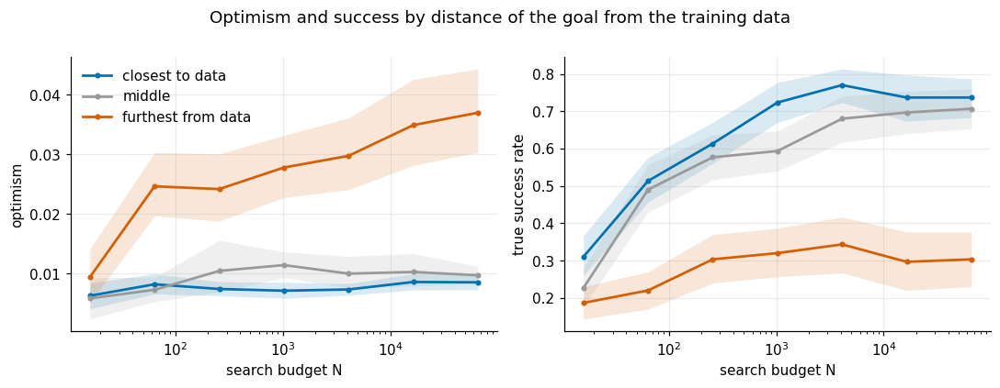

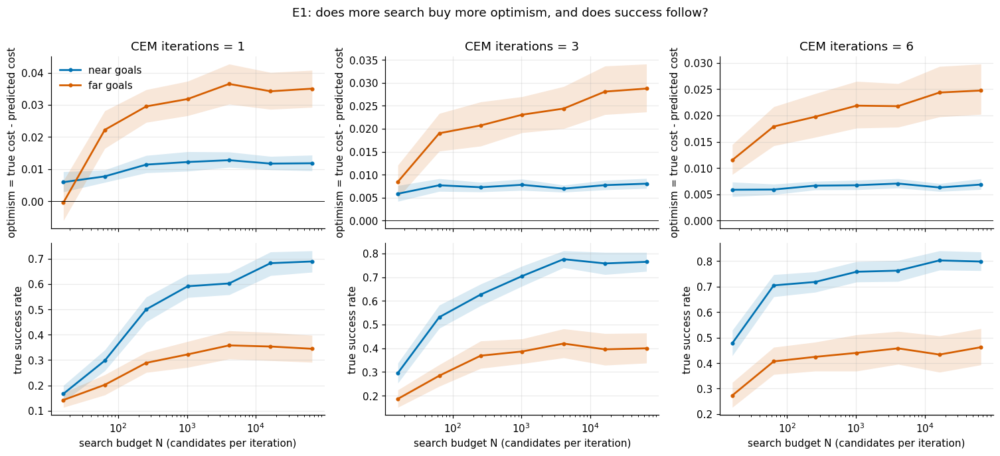

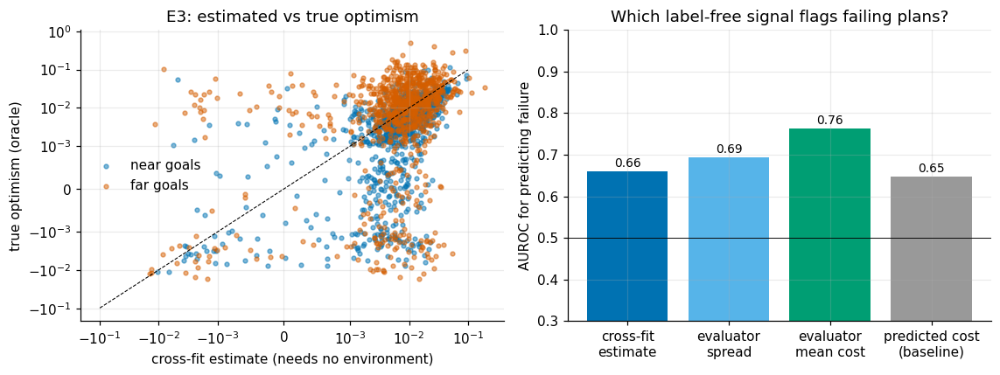

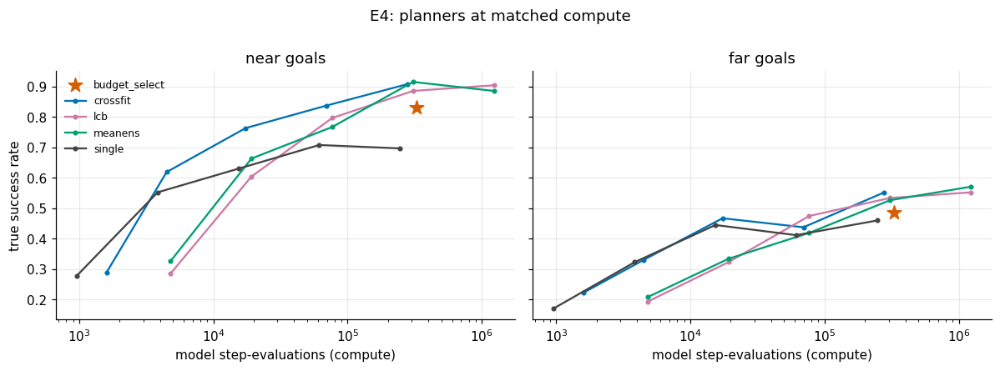

In [28]:
# 5) Load GPU results (full run if present, otherwise the smoke run) and reuse the same figures.
tag = "full" if os.path.exists("results/gpu_sweep_full.csv") else ("smoke" if os.path.exists("results/gpu_sweep_smoke.csv") else None)
if tag is None:
    print("No GPU result CSVs in ./results yet. Run cell 2 and read its output for errors.")
else:
    dg, dgp = pd.read_csv(f"results/gpu_sweep_{tag}.csv"), pd.read_csv(f"results/gpu_planners_{tag}.csv")
    for d_ in (dg, dgp): d_["pair"] = d_["ensemble"] * 1000 + d_["pair"]
    print(f"loaded {tag} run:", len(dg), "sweep rows,", len(dgp), "planner rows")
    print(dg.groupby(["tag", "N"])[["pred", "oracle", "optimism", "success"]].mean().round(3))
    if tag == "full":
        print(P.gates(dg, dgp).round(3).to_string(index=False))
        print(P.support_interaction(dg).round(4).to_string(index=False))
        P.fig_support(dg).savefig("figures/fig_support_gpu.png", dpi=160, bbox_inches="tight")
        P.fig_scaling(dg, iters_list=(1, 3, 6)).savefig("figures/fig_E1_scaling_gpu.png", dpi=160, bbox_inches="tight")
        P.fig_estimator(dg)[0].savefig("figures/fig_E3_estimator_gpu.png", dpi=160, bbox_inches="tight")
        P.fig_planners(dgp).savefig("figures/fig_E4_planners_gpu.png", dpi=160, bbox_inches="tight")
        plt.show()

loaded full run: 18900 sweep rows, 11340 planner rows
             pred  oracle  optimism  success
tag  N                                      
far  16     0.054   0.061     0.006    0.201
     64     0.022   0.042     0.020    0.298
     256    0.011   0.034     0.023    0.361
     1024   0.006   0.032     0.026    0.383
     4096   0.003   0.031     0.028    0.412
     16384  0.001   0.030     0.029    0.394
     65536  0.001   0.030     0.030    0.402
near 16     0.036   0.042     0.006    0.313
     64     0.016   0.023     0.007    0.511
     256    0.008   0.017     0.008    0.615
     1024   0.004   0.013     0.009    0.684
     4096   0.002   0.011     0.009    0.713
     16384  0.001   0.010     0.009    0.747
     65536  0.001   0.009     0.009    0.750
                        gate                                  subset                              metric  value     lo    hi         verdict
    G1 optimism grows with N                              near goals  optimism(N=6553

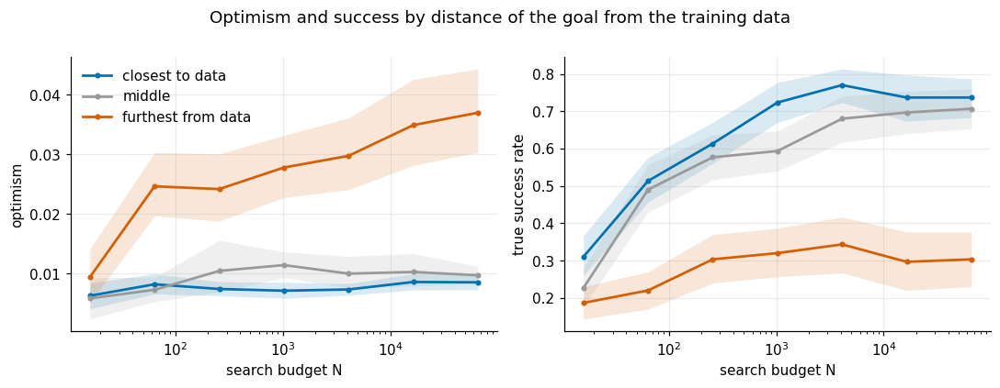

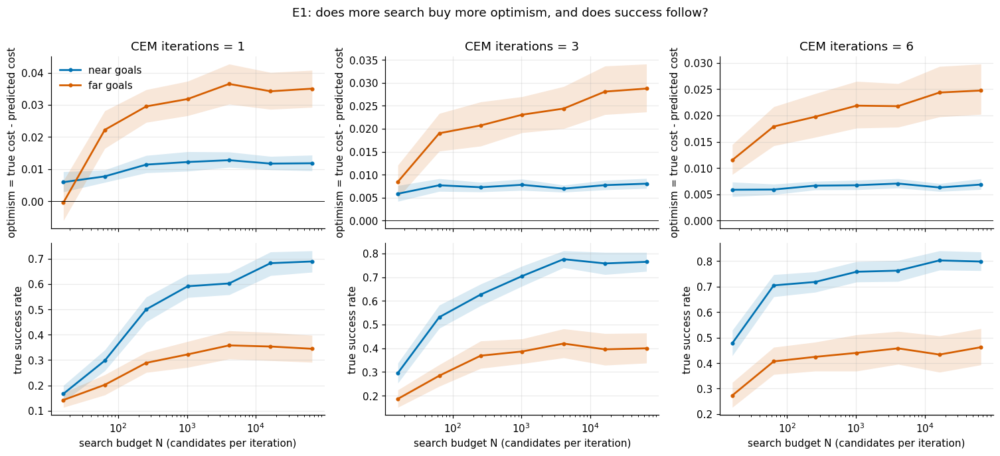

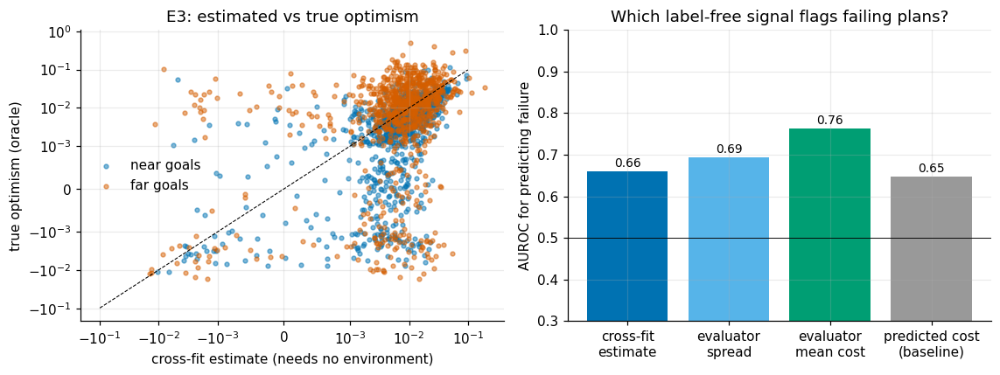

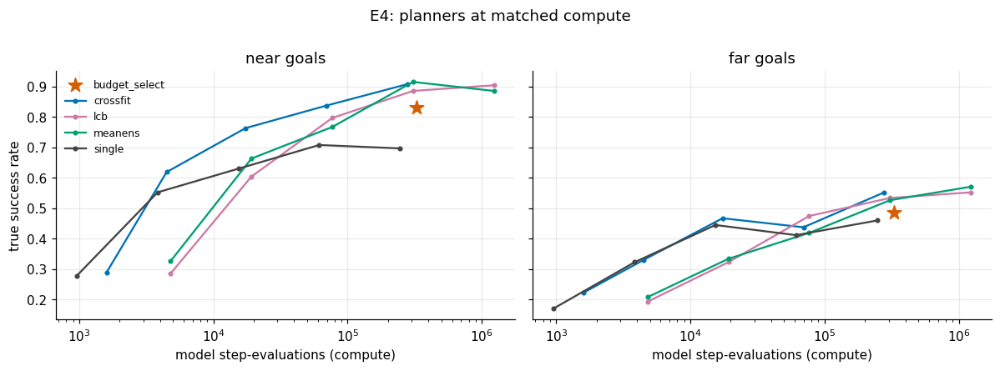

In [29]:
# 5) Load GPU results (full run if present, otherwise the smoke run) and reuse the same figures.
tag = "full" if os.path.exists("results/gpu_sweep_full.csv") else ("smoke" if os.path.exists("results/gpu_sweep_smoke.csv") else None)
if tag is None:
    print("No GPU result CSVs in ./results yet. Run cell 2 and read its output for errors.")
else:
    dg, dgp = pd.read_csv(f"results/gpu_sweep_{tag}.csv"), pd.read_csv(f"results/gpu_planners_{tag}.csv")
    for d_ in (dg, dgp): d_["pair"] = d_["ensemble"] * 1000 + d_["pair"]
    print(f"loaded {tag} run:", len(dg), "sweep rows,", len(dgp), "planner rows")
    print(dg.groupby(["tag", "N"])[["pred", "oracle", "optimism", "success"]].mean().round(3))
    if tag == "full":
        print(P.gates(dg, dgp).round(3).to_string(index=False))
        print(P.support_interaction(dg).round(4).to_string(index=False))
        print(P.crossfit_check(dg, dgp).round(3).to_string(index=False))   # is the cross-fit gain more than extra compute?
        P.fig_support(dg).savefig("figures/fig_support_gpu.png", dpi=160, bbox_inches="tight")
        P.fig_scaling(dg, iters_list=(1, 3, 6)).savefig("figures/fig_E1_scaling_gpu.png", dpi=160, bbox_inches="tight")
        P.fig_estimator(dg)[0].savefig("figures/fig_E3_estimator_gpu.png", dpi=160, bbox_inches="tight")
        P.fig_planners(dgp).savefig("figures/fig_E4_planners_gpu.png", dpi=160, bbox_inches="tight")
        plt.show()

loaded full run: 18900 sweep rows, 11340 planner rows
             pred  oracle  optimism  success
tag  N                                      
far  16     0.054   0.061     0.006    0.201
     64     0.022   0.042     0.020    0.298
     256    0.011   0.034     0.023    0.361
     1024   0.006   0.032     0.026    0.383
     4096   0.003   0.031     0.028    0.412
     16384  0.001   0.030     0.029    0.394
     65536  0.001   0.030     0.030    0.402
near 16     0.036   0.042     0.006    0.313
     64     0.016   0.023     0.007    0.511
     256    0.008   0.017     0.008    0.615
     1024   0.004   0.013     0.009    0.684
     4096   0.002   0.011     0.009    0.713
     16384  0.001   0.010     0.009    0.747
     65536  0.001   0.009     0.009    0.750
                        gate                                  subset                              metric  value     lo    hi         verdict
    G1 optimism grows with N                              near goals  optimism(N=6553

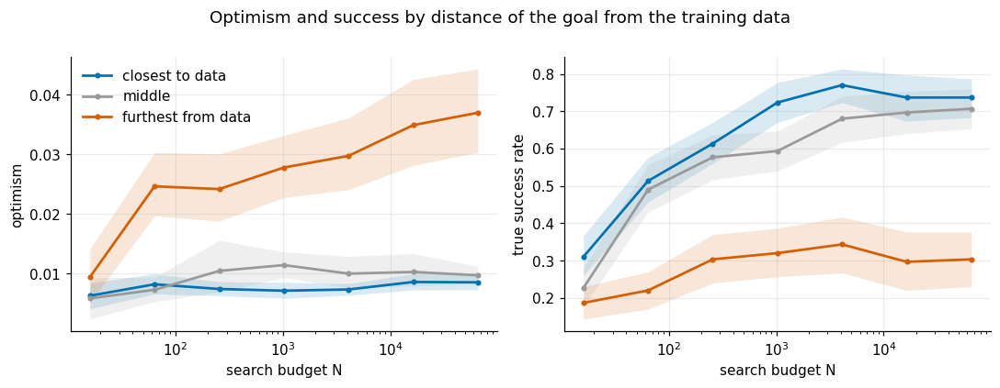

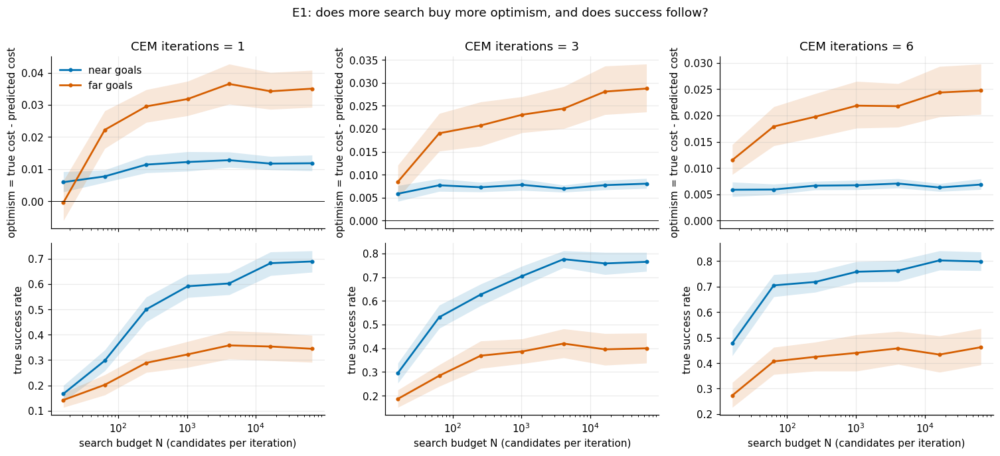

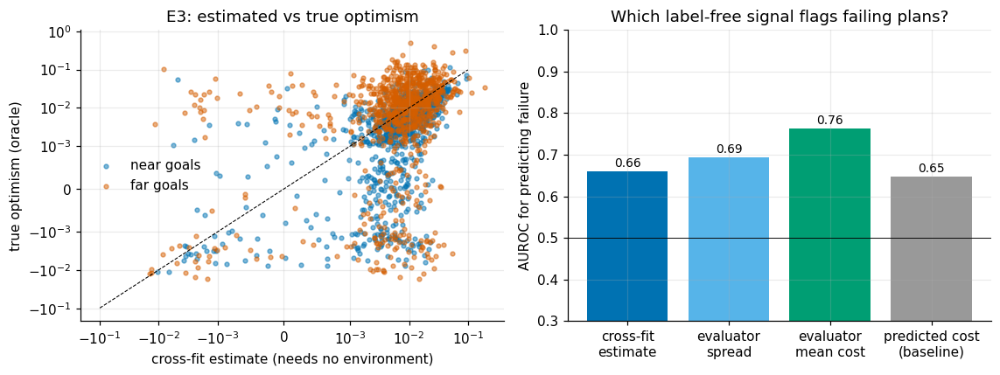

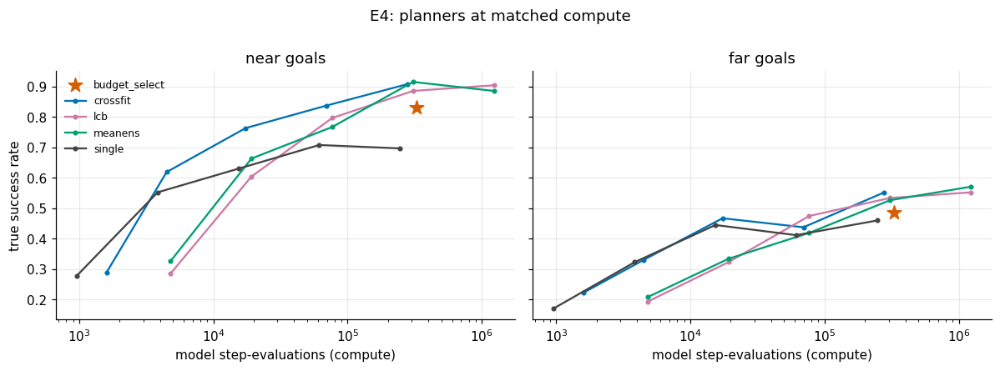

In [31]:
# 5) Load GPU results (full run if present, otherwise the smoke run) and reuse the same figures.
importlib.reload(W); importlib.reload(P)   # pick up a replaced wcp_plots.py without restarting the kernel
assert hasattr(P, "crossfit_check") and hasattr(P, "support_interaction"), "Old wcp_plots.py: replace it with the latest copy."
tag = "full" if os.path.exists("results/gpu_sweep_full.csv") else ("smoke" if os.path.exists("results/gpu_sweep_smoke.csv") else None)
if tag is None:
    print("No GPU result CSVs in ./results yet. Run cell 2 and read its output for errors.")
else:
    dg, dgp = pd.read_csv(f"results/gpu_sweep_{tag}.csv"), pd.read_csv(f"results/gpu_planners_{tag}.csv")
    for d_ in (dg, dgp): d_["pair"] = d_["ensemble"] * 1000 + d_["pair"]
    print(f"loaded {tag} run:", len(dg), "sweep rows,", len(dgp), "planner rows")
    print(dg.groupby(["tag", "N"])[["pred", "oracle", "optimism", "success"]].mean().round(3))
    if tag == "full":
        print(P.gates(dg, dgp).round(3).to_string(index=False))
        print(P.support_interaction(dg).round(4).to_string(index=False))
        dg2 = P.add_pair_meta(dg, M=60)   # M must match --n-pairs of the GPU run
        print("with start-goal distance as control:"); print(P.support_interaction_ctrl(dg2).round(4).to_string(index=False))
        print(P.crossfit_check(dg, dgp).round(3).to_string(index=False))   # is the cross-fit gain more than extra compute?
        P.fig_support(dg).savefig("figures/fig_support_gpu.png", dpi=160, bbox_inches="tight")
        P.fig_scaling(dg, iters_list=(1, 3, 6)).savefig("figures/fig_E1_scaling_gpu.png", dpi=160, bbox_inches="tight")
        P.fig_estimator(dg)[0].savefig("figures/fig_E3_estimator_gpu.png", dpi=160, bbox_inches="tight")
        P.fig_planners(dgp).savefig("figures/fig_E4_planners_gpu.png", dpi=160, bbox_inches="tight")
        plt.show()

## D. Decision gates (pre-registered in the plan)
Computed automatically with cluster-bootstrap 95% CIs over start-goal pairs. Do not change the thresholds after looking.

* **G1** optimism at the largest N exceeds optimism at the smallest N (CI above 0).
* **G2** success at the largest N versus a mid-range N: reports REVERSAL / SATURATED / STILL IMPROVING.
* **G3** cross-fit estimate tracks true optimism (Spearman >= 0.3 within each budget cell), and flags failures better than the predicted cost alone (AUROC >= 0.7).
* **G4** a bias-aware planner beats single-model CEM on far goals (CI above 0), with its compute multiple reported.

In [18]:
G = P.gates(df, dp)
print(G.round(3).to_string(index=False))

                        gate                                  subset                              metric  value     lo    hi   verdict
    G1 optimism grows with N                              near goals  optimism(N=16384) - optimism(N=16)  0.006 -0.002 0.013      FAIL
    G1 optimism grows with N                               far goals  optimism(N=16384) - optimism(N=16)  0.023  0.015 0.032      PASS
   G2 success vs more search                              near goals  success(N=16384) - success(N=1024)  0.039 -0.033 0.106 SATURATED
   G2 success vs more search                               far goals  success(N=16384) - success(N=1024)  0.033 -0.039 0.106 SATURATED
G3 estimator tracks optimism                                     all      Spearman within (N,iters) cell  0.392    NaN   NaN      PASS
G3b estimator flags failures                                     all AUROC(est) vs AUROC(predicted cost)  0.653  0.642   NaN      FAIL
    G4 planner vs single CEM      far goals, crossfit (

## Stage 2 (only if the gates pass): released checkpoints
Not implemented here on purpose: it depends on external repos whose current APIs I could not verify.
Plan: (a) E0 reproduce a published Push-T success number with the released DINO-WM / JEPA-WM checkpoint before any new claim;
(b) rerun E1 and E3 with a reduced N sweep (planning is slow: one public report puts DINO-WM at roughly 5,800 s for 50
trajectories on an L40S); (c) TD-MPC2 released checkpoints with an MPPI sample sweep. Use `modal_app.py` as the template:
swap the MLP ensemble for the released model and keep `W.oracle`-style simulator scoring.

In [35]:
rc = run([sys.executable, "-m", "modal", "run", "modal_probe.py"])
print("exit code", rc)

- Initializing...
✓ Initialized. View run at 
https://modal.com/apps/smjubaer-0-00/main/ap-UAqSMWP2xM9ZtlAHK0IHlN
- Initializing...
- Initializing...

- Creating objects...
| Creating objects...
- Creating objects...
| Creating objects...
└── - Creating mount e:\Web_downloads\icwm_pilot\icwm_pilot\modal_probe.py: 
    Uploaded 0/1 files
- Creating objects...
└── | Creating mount e:\Web_downloads\icwm_pilot\icwm_pilot\modal_probe.py: 
    Uploaded 0/1 files
| Creating objects...
└── - Creating mount e:\Web_downloads\icwm_pilot\icwm_pilot\modal_probe.py: 
    Uploaded 0/1 files
- Creating objects...
└── | Creating mount e:\Web_downloads\icwm_pilot\icwm_pilot\modal_probe.py: 
    Uploaded 0/1 files
| Creating objects...
└── - Creating mount e:\Web_downloads\icwm_pilot\icwm_pilot\modal_probe.py: 
    Uploaded 0/1 files
- Creating objects...
└── | Creating mount e:\Web_downloads\icwm_pilot\icwm_pilot\modal_probe.py: 
    Uploaded 0/1 files
| Creating objects...
└── - Creating mount e:\Web_d

In [36]:
print(open("results/probe_summary.txt", encoding="utf-8").read()[:12000])

COMMIT: 13cf1d9c7e476f53c17714d2e0f1dc239a883ce0
=== TREE (depth 3, dirs) ===
.
./app
./app/plan_common
./app/plan_common/datasets
./app/plan_common/models
./app/plan_common/plot
./app/vjepa_wm
./app/vjepa_wm/modelcustom
./assets
./configs
./configs/evals
./configs/evals/simu_env_planning
./configs/online_plan_evals
./configs/online_plan_evals/droid
./configs/online_plan_evals/mw
./configs/online_plan_evals/mz
./configs/online_plan_evals/pt
./configs/online_plan_evals/rcasa_custom
./configs/online_plan_evals/wall
./configs/vjepa_wm
./configs/vjepa_wm/droid_final_sweep
./configs/vjepa_wm/mw_final_sweep
./configs/vjepa_wm/mz
./configs/vjepa_wm/mz_sweep
./configs/vjepa_wm/pt_sweep
./configs/vjepa_wm/vm2m
./configs/vjepa_wm/wall_sweep
./evals
./evals/simu_env_planning
./evals/simu_env_planning/assets
./evals/simu_env_planning/base_configs
./evals/simu_env_planning/envs
./evals/simu_env_planning/planning
./evals/unroll_decode
./src
./src/datasets
./src/datasets/utils
./src/masks
./src/model

In [37]:
import re
t = open("results/probe_summary.txt", encoding="utf-8").read()
parts = re.split(r"(?=##### FILE )", t)
want = ("planning/planner.py", "planning/objectives.py", "simu_env_planning/envs",
        "modelcustom/simu_env_planning", "simu_env_planning/README")
keep = [p for p in parts if p.startswith("##### FILE") and any(w in p.split("\n")[0] for w in want)]
head = [p for p in parts if not p.startswith("##### FILE")]
# grep sections (entry points, eval_episodes/success/step) are in the head part
open("results/probe_key.txt", "w", encoding="utf-8").write(
    "\n".join(head)[-14000:] + "\n" + "\n".join(k[:14000] for k in keep))
print(len(open("results/probe_key.txt", encoding="utf-8").read()), "chars")

33298 chars


### Phase 2 step 0b - targeted probe (GPU, ~$0.15)
Fixes the paths and tries to install the repo and load the Wall models. Attach `results/probe2_key.txt` and `results/probe2_install.txt` to the chat.

In [40]:
rc = run([sys.executable, "-m", "modal", "run", "modal_probe2.py"])
print("exit code", rc)

- Initializing...
✓ Initialized. View run at 
https://modal.com/apps/smjubaer-0-00/main/ap-SDQ3047Lo8hYoWlZMFliDs
- Initializing...
- Initializing...

- Creating objects...
| Creating objects...
- Creating objects...
| Creating objects...
└── - Creating mount e:\Web_downloads\icwm_pilot\icwm_pilot\modal_probe2.py: 
    Uploaded 0/1 files
- Creating objects...
└── \ Creating mount e:\Web_downloads\icwm_pilot\icwm_pilot\modal_probe2.py: 
    Uploaded 0/1 files
| Creating objects...
└── / Creating mount e:\Web_downloads\icwm_pilot\icwm_pilot\modal_probe2.py: 
    Uploaded 0/1 files
- Creating objects...
└── | Creating mount e:\Web_downloads\icwm_pilot\icwm_pilot\modal_probe2.py: 
    Uploaded 0/1 files
| Creating objects...
└── - Creating mount e:\Web_downloads\icwm_pilot\icwm_pilot\modal_probe2.py: 
    Uploaded 0/1 files
- Creating objects...
└── | Creating mount e:\Web_downloads\icwm_pilot\icwm_pilot\modal_probe2.py: 
    Uploaded 0/1 files
| Creating objects...
└── - Creating mount e:

### Phase 2a - released Wall checkpoints through the repo's own eval (Modal L4)
Run the three cells in order. Attach `results/wall_data_jepa.txt` after the first one (the dataset layout and the code I still need), then the repro and sweep outputs.
`data` ~ $0.2, `repro` (96 episodes, one setting) a few dollars at most; check the time it prints before the sweep.

In [52]:
rc = run([sys.executable, "-m", "modal", "run", "modal_wall.py", "--stage", "data"])

- Initializing...
✓ Initialized. View run at 
https://modal.com/apps/smjubaer-0-00/main/ap-s45AoQdeyr0bIRbKNgvwL6
- Initializing...
- Initializing...

- Creating objects...
| Creating objects...
- Creating objects...
| Creating objects...
- Creating objects...
└── - Creating mount e:\Web_downloads\icwm_pilot\icwm_pilot\modal_wall.py: 
    Uploaded 0/1 files
| Creating objects...
└── | Creating mount e:\Web_downloads\icwm_pilot\icwm_pilot\modal_wall.py: 
    Uploaded 0/1 files
- Creating objects...
└── - Creating mount e:\Web_downloads\icwm_pilot\icwm_pilot\modal_wall.py: 
    Uploaded 0/1 files
| Creating objects...
└── | Creating mount e:\Web_downloads\icwm_pilot\icwm_pilot\modal_wall.py: 
    Uploaded 0/1 files
- Creating objects...
└── - Creating mount e:\Web_downloads\icwm_pilot\icwm_pilot\modal_wall.py: 
    Uploaded 0/1 files
| Creating objects...
└── | Creating mount e:\Web_downloads\icwm_pilot\icwm_pilot\modal_wall.py: 
    Uploaded 0/1 files
- Creating objects...
└── - Creatin

In [5]:
rc = run([sys.executable, "-m", "modal", "run", "modal_wall.py", "--stage", "repro", "--model", "jepa", "--episodes", "96"])

- Initializing...
✓ Initialized. View run at 
https://modal.com/apps/smjubaer-0-00/main/ap-PHIdlS7SMkiGotpwCuU0yi
- Initializing...
- Initializing...

- Creating objects...
| Creating objects...
- Creating objects...
| Creating objects...
└── - Creating mount e:\Web_downloads\icwm_pilot\icwm_pilot\modal_wall.py: 
    Uploaded 0/1 files
- Creating objects...
└── | Creating mount e:\Web_downloads\icwm_pilot\icwm_pilot\modal_wall.py: 
    Uploaded 0/1 files
| Creating objects...
└── - Creating mount e:\Web_downloads\icwm_pilot\icwm_pilot\modal_wall.py: 
    Uploaded 0/1 files
- Creating objects...
└── | Creating mount e:\Web_downloads\icwm_pilot\icwm_pilot\modal_wall.py: 
    Finalizing index of 1 files
| Creating objects...
└── - Creating mount e:\Web_downloads\icwm_pilot\icwm_pilot\modal_wall.py: 
    Finalizing index of 1 files
- Creating objects...
└── | Creating mount e:\Web_downloads\icwm_pilot\icwm_pilot\modal_wall.py: 
    Finalizing index of 1 files
| Creating objects...
└── - Cr

In [6]:
# only after repro matches the published number:
rc = run([sys.executable, "-m", "modal", "run", "modal_wall.py", "--stage", "sweep", "--model", "jepa", "--episodes", "48"])

- Initializing...
✓ Initialized. View run at 
https://modal.com/apps/smjubaer-0-00/main/ap-HAj41y2Hk4WFF3LF1ylCBR
- Initializing...
- Initializing...

- Creating objects...
\ Creating objects...
/ Creating objects...
| Creating objects...
└── - Creating mount e:\Web_downloads\icwm_pilot\icwm_pilot\modal_wall.py: 
    Uploaded 0/1 files
- Creating objects...
└── | Creating mount e:\Web_downloads\icwm_pilot\icwm_pilot\modal_wall.py: 
    Uploaded 0/1 files
| Creating objects...
└── - Creating mount e:\Web_downloads\icwm_pilot\icwm_pilot\modal_wall.py: 
    Uploaded 0/1 files
- Creating objects...
└── | Creating mount e:\Web_downloads\icwm_pilot\icwm_pilot\modal_wall.py: 
    Finalizing index of 1 files
| Creating objects...
└── - Creating mount e:\Web_downloads\icwm_pilot\icwm_pilot\modal_wall.py: 
    Finalizing index of 1 files
- Creating objects...
└── | Creating mount e:\Web_downloads\icwm_pilot\icwm_pilot\modal_wall.py: 
    Finalizing index of 1 files
| Creating objects...
└── 🔨 Cr

KeyboardInterrupt: 

### Phase 2b - held-out re-ranking on the real Wall models (lean runner)
The repro (27 episodes) gave 0.741 [0.553, 0.868], consistent with the published 78.8, so the pipeline is trustworthy. Run the smoke test first and attach its output (it prints shapes, timing and an fp32-vs-bf16 check). Only then launch the full run.

In [11]:
rc = run([sys.executable, "-m", "modal", "run", "modal_wall_2b.py", "--smoke"])

- Initializing...
✓ Initialized. View run at 
https://modal.com/apps/smjubaer-0-00/main/ap-eKsgJRRv8oXwzbIGgWxln6
- Initializing...
- Initializing...

- Creating objects...
| Creating objects...
- Creating objects...
| Creating objects...
└── - Creating mount e:\Web_downloads\icwm_pilot\icwm_pilot\modal_wall_2b.py: 
    Uploaded 0/1 files
- Creating objects...
└── | Creating mount e:\Web_downloads\icwm_pilot\icwm_pilot\modal_wall_2b.py: 
    Uploaded 0/1 files
| Creating objects...
└── - Creating mount e:\Web_downloads\icwm_pilot\icwm_pilot\modal_wall_2b.py: 
    Uploaded 0/1 files
- Creating objects...
└── | Creating mount e:\Web_downloads\icwm_pilot\icwm_pilot\modal_wall_2b.py: 
    Uploaded 0/1 files
| Creating objects...
└── - Creating mount e:\Web_downloads\icwm_pilot\icwm_pilot\modal_wall_2b.py: 
    Uploaded 0/1 files
- Creating objects...
└── | Creating mount e:\Web_downloads\icwm_pilot\icwm_pilot\modal_wall_2b.py: 
    Uploaded 0/1 files
| Creating objects...
└── - Creating mo

In [20]:
# after the smoke test is clean: 48 start/goal pairs on 4 parallel GPUs
rc = run([sys.executable, "-m", "modal", "run", "--detach", "modal_wall_2b.py", "--pairs", "48", "--shards", "4", "--iters", "8"])

Note that running a local entrypoint in detached mode only keeps the last triggered Modal function alive after the parent process has been killed or disconnected.
- Initializing...
✓ Initialized. View run at 
https://modal.com/apps/smjubaer-0-00/main/ap-nC2M8rrAu0FD00A5UkqANx
- Initializing...
- Initializing...

- Creating objects...
\ Creating objects...
- Creating objects...
| Creating objects...
- Creating objects...
└── - Creating mount e:\Web_downloads\icwm_pilot\icwm_pilot\modal_wall_2b.py: 
    Uploaded 0/1 files
| Creating objects...
└── | Creating mount e:\Web_downloads\icwm_pilot\icwm_pilot\modal_wall_2b.py: 
    Uploaded 0/1 files
- Creating objects...
└── - Creating mount e:\Web_downloads\icwm_pilot\icwm_pilot\modal_wall_2b.py: 
    Uploaded 0/1 files
| Creating objects...
└── | Creating mount e:\Web_downloads\icwm_pilot\icwm_pilot\modal_wall_2b.py: 
    Uploaded 0/1 files
- Creating objects...
└── - Creating mount e:\Web_downloads\icwm_pilot\icwm_pilot\modal_wall_2b.py: 
 